# Рекомендательная задача, взаимодействия и оценка

Результат рекомендательной системы — упорядоченный список подходящих объектов для конкретного контекста. Здесь рассматривается открытие новых товаров: уже встречавшиеся пользователю позиции исключаются из выдачи. Такой сценарий отличается от повторного заказа расходных товаров.

Материал соединяет исходные заказы с отдельным учебным журналом взаимодействий. Все просмотры, добавления в корзину, предпочтения и дополнительные атрибуты каталога в этом журнале синтетические. Качество на нём характеризует учебный эксперимент.

Порядок изучения: постановка задачи, структура событий, временная проверка, метрики списка, простые алгоритмы и ограничения выводов. Общие операции Pandas и правила разделения ML-данных из предыдущих модулей используются без повторного разбора.

## Постановка задачи и границы исходных данных

Пользователь, объект, контекст и момент расчёта определяют запрос. Кандидаты — объекты, которые допустимо показать; ранжирование — присвоение им порядка; top-K — первые K позиций после ограничений. Идентификатор связывает записи, но его числовая величина не описывает предпочтение.

Оценка релевантности в этом модуле основана на будущей покупке нового товара. Она не измеряет удовлетворённость и не превращает все остальные товары в доказанно неинтересные.

In [1]:
# Шаг М4.01.01 — Среда и расположение данных
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse
from sklearn.preprocessing import normalize
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.decomposition import TruncatedSVD
from IPython.display import display

pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.figsize": (9, 4), "font.size": 10})
module_name = "Модуль 4 Рекомендательные системы"
candidates = [candidate for root in [Path.cwd(), *Path.cwd().parents]
              for candidate in (root, root / "course" / "practice" / module_name)]
MODULE_DIR = next(p for p in candidates if p.name == module_name and p.is_dir())
DATA_DIR = MODULE_DIR / "data"
SOURCE_DIR = MODULE_DIR.parent.parent / "data"
print("Каталог материалов:", MODULE_DIR.name)

Каталог материалов: Модуль 4 Рекомендательные системы


Событие заказа не является пользовательской оценкой по шкале звёзд. Статусы характеризуют исполнение операции. Возвраты и отмены не назначаются автоматически отрицательными предпочтениями.

Рекомендательный журнал должен отвечать на вопрос о событии, времени, пользователе и объекте. Итоговые продажи не восстанавливают показы: отсутствие заказа может означать отсутствие знакомства с товаром. Поэтому по этой таблице невозможно посчитать честный CTR, то есть отношение кликов к показам, или утверждать, что непокупка означает отрицательный выбор.

Состояние исполнения заказа — отдельная бизнес-информация. Оно помогает определить допустимый положительный сигнал, но не заменяет обратную связь об удовлетворённости.

In [2]:
# Шаг М4.01.02 — Что содержится в исходных заказах
products_source = pd.read_csv(SOURCE_DIR / "products.csv")
orders_source = pd.read_csv(SOURCE_DIR / "orders.csv", parse_dates=["order_ts"])
display(orders_source.head(4))
display(products_source.head(4))
display(orders_source.groupby("status").size().rename("строк").to_frame())

,order_id,order_ts,customer_id,city,product_id,category,qty,price,amount,status
0,1,2026-01-17 08:50:04,8384,Санкт-Петербург,1104,Одежда,1,9700,9700,delivered
1,2,2026-07-13 14:51:05,11971,Краснодар,1471,Продукты,1,480,480,delivered
2,3,2026-11-03 13:42:32,19274,Новосибирск,887,Обувь,1,7630,7630,delivered
3,4,2026-03-19 16:38:33,14821,Москва,79,Одежда,1,11660,11660,returned


,product_id,category,name,price
0,1,Электроника,Электроника товар 1,61790
1,2,Обувь,Обувь товар 2,15690
2,3,Электроника,Электроника товар 3,29120
3,4,Книги,Книги товар 4,1760


,строк
status,
cancelled,17980
delivered,164061
in_transit,7914
returned,10045


Гранулярность определяет, что обозначает одна строка. Несколько строк одной корзины могли бы содержать разные товары с общим идентификатором заказа. Здесь order_id уникален, поэтому корзина из нескольких товаров не представлена. Совместность по клиенту относится к истории человека, а не автоматически к одной сессии.

Проверка внешнего ключа product_id предотвращает потерю событий при соединении с каталогом. Отсутствующее описание и неизвестный товар требуют явного решения.

In [3]:
# Шаг М4.01.03 — Гранулярность заказа и доступность признаков
source_check = pd.Series({
    "строк":len(orders_source), "различных order_id":orders_source.order_id.nunique(),
    "клиентов":orders_source.customer_id.nunique(), "товаров":orders_source.product_id.nunique(),
    "товаров без категории":products_source.category.isna().sum(),
    "неизвестных product_id":(~orders_source.product_id.isin(products_source.product_id)).sum()
})
display(source_check.to_frame("значение"))

,значение
строк,200000
различных order_id,200000
клиентов,19059
товаров,2000
товаров без категории,0
неизвестных product_id,0


Число разных покупателей уменьшает влияние нескольких крупных клиентов. Рейтинг по выручке, напротив, усилил бы дорогие товары; рейтинг по количеству — часто покупаемые позиции. Ни одно определение популярности не универсально.

Универсальный список может оставаться сильной базой при короткой истории. Его полезность проверяется до усложнения алгоритма, а выбранный способ подсчёта сохраняется на всех временных этапах.

In [4]:
# Шаг М4.01.04 — Популярность по доставленным заказам
delivered = orders_source[orders_source.status.eq("delivered")]
source_popularity = delivered.drop_duplicates(["customer_id","product_id"]).groupby("product_id").size()
display(source_popularity.nlargest(8).rename("различных покупателей").to_frame()
        .join(products_source.set_index("product_id")[["name","category"]]))

,различных покупателей,name,category
product_id,,,
516,89,Книги товар 516,Книги
706,89,Красота товар 706,Красота
1292,87,Электроника товар 1292,Электроника
480,86,Красота товар 480,Красота
557,86,Электроника товар 557,Электроника
802,86,Электроника товар 802,Электроника
1689,86,Обувь товар 1689,Обувь
1723,86,Электроника товар 1723,Электроника


## Учебный журнал и представление истории

Каталог содержит 180 товаров из исходного products.csv: по 20 на категорию. Поля collection, usage, description и признак no_train_events созданы для учебного эксперимента. Они не являются фактическими характеристиками исходных товаров.

События 300 синтетических пользователей формируются с фиксированным seed. Генератор задаёт предпочтения категорий и коллекций, небольшую общую популярность и случайность. В моделях скрытые параметры генератора не используются.

Генератор задаёт механизм происхождения данных: предпочтения категории и коллекции влияют на вероятность выбора, но выбор остаётся случайным. Скрытые параметры пользователя не становятся признаками. Алгоритмы получают только наблюдаемый результат взаимодействий и разрешённые атрибуты каталога.

Фиксированный seed обеспечивает повторяемость вычислений при неизменных библиотечных условиях. Он не делает искусственную выборку представительной для реального магазина. Исходные заказы при генерации не изменяются.

In [5]:
# Шаг М4.01.05 — Воспроизводимый учебный набор
# Учебные атрибуты и взаимодействия полностью синтетические.
seed = 104
rng = np.random.default_rng(seed)
source_catalog = pd.read_csv(SOURCE_DIR / "products.csv")
catalog = (source_catalog.sort_values("product_id").groupby("category", group_keys=False)
           .head(20).sort_values("product_id").reset_index(drop=True))
within_category = catalog.groupby("category").cumcount()
catalog["collection"] = within_category.map(lambda i: ["базовая", "активная", "уютная", "премиальная"][i % 4])
catalog["usage"] = within_category.map(lambda i: ["дом", "поездка", "подарок"][i % 3])
catalog["description"] = catalog.category + ". Учебная коллекция: " + catalog.collection + ". Сценарий: " + catalog.usage + "."
catalog["no_train_events"] = within_category.eq(19)
categories = sorted(catalog.category.unique())
item_ids = catalog.product_id.to_numpy()
category_index = pd.Categorical(catalog.category, categories=categories).codes
style_index = within_category.to_numpy() % 4
catalog_popularity = 1 / np.sqrt(1 + np.arange(len(catalog)) % 17)
rows = []
event_id = 1
for user_id in range(1, 301):
    favorite = int(rng.integers(len(categories)))
    secondary = (favorite + int(rng.integers(1, len(categories)))) % len(categories)
    style = int(rng.integers(4))
    preference = (2.8*(category_index==favorite) + 0.9*(category_index==secondary)
                  + 1.5*(style_index==style) + np.log(catalog_popularity))
    previous = set()
    phases = [
        ("2025-01-01", 90, 18, user_id <= 280),
        ("2025-04-01", 30, 9, user_id <= 290),
        ("2025-05-01", 31, 9, True),
    ]
    for phase_number, (start, days, number, enabled) in enumerate(phases):
        if not enabled:
            continue
        eligible = np.array([i for i, pid in enumerate(item_ids)
                             if pid not in previous and not (phase_number == 0 and catalog.no_train_events.iloc[i])])
        weights = np.exp(preference[eligible] - preference[eligible].max())
        chosen = rng.choice(eligible, size=number, replace=False, p=weights/weights.sum())
        for position, item_index in enumerate(chosen):
            kind = (rng.choice(["view", "cart", "purchase"], p=[.5,.2,.3]) if phase_number==0
                    else (["purchase"]*4+["view"]*3+["cart"]*2)[position])
            timestamp = pd.Timestamp(start) + pd.Timedelta(seconds=int(rng.integers(days*86400)))
            rows.append((event_id,user_id,int(item_ids[item_index]),timestamp,kind))
            event_id += 1
            if phase_number==0 and rng.random() < .18:
                # Повторное событие того же пользователя, не дубль строки выгрузки.
                rows.append((event_id,user_id,int(item_ids[item_index]),timestamp+pd.Timedelta(seconds=1),"view"))
                event_id += 1
        previous.update(item_ids[chosen])
events = pd.DataFrame(rows,columns=["event_id","user_id","product_id","timestamp","event_type"])
events = pd.concat([events,events.iloc[:30]],ignore_index=True).sort_values(["timestamp","event_id"]).reset_index(drop=True)
catalog.to_csv(DATA_DIR/"reco_catalog.csv",index=False)
events.to_csv(DATA_DIR/"reco_events.csv",index=False,date_format="%Y-%m-%d %H:%M:%S")
display(pd.DataFrame({"показатель":["товары","пользователи","строки выгрузки","уникальные события","дубли экспорта"],
                      "значение":[len(catalog),events.user_id.nunique(),len(events),events.event_id.nunique(),
                                  events.duplicated("event_id").sum()]}))

,показатель,значение
0,товары,180
1,пользователи,300
2,строки выгрузки,11264
3,уникальные события,11234
4,дубли экспорта,30


Дедупликация по содержимому всей строки и дедупликация по идентификатору события решают разные задачи. Два самостоятельных просмотра могут иметь одинаковые параметры, но разные event_id. Удаление одного из них занизило бы интенсивность.

Одинаковый event_id с разным содержимым является конфликтом источника. Такой конфликт нельзя разрешать случайным сохранением первой строки; здесь сначала проверяется непротиворечивость повторов.

In [6]:
# Шаг М4.01.06 — Дубли экспорта и самостоятельные события
raw_events = pd.read_csv(DATA_DIR/"reco_events.csv",parse_dates=["timestamp"])
conflicts = raw_events.groupby("event_id")[["user_id","product_id","timestamp","event_type"]].nunique().max()
assert conflicts.max() == 1
events = raw_events.drop_duplicates("event_id").copy()
assert events.event_id.is_unique and events.timestamp.notna().all()
assert events.event_type.isin(["view","cart","purchase"]).all()
display(pd.Series({"строк до очистки":len(raw_events),"событий после очистки":len(events),
                   "пар user-item":len(events[["user_id","product_id"]].drop_duplicates())}).to_frame("значение"))

,значение
строк до очистки,11264
событий после очистки,11234
пар user-item,10350


Количество слабых сигналов часто значительно больше числа покупок. Без весов модель может в основном описывать привычку просматривать карточки. Указанные веса являются настраиваемым допущением; их смысл связан с уверенностью в сигнале, а не с пользовательской шкалой оценки.

Проверочное окно содержит только покупки как положительные события. Вход модели может быть шире критерия её результата.

event_type,cart,purchase,view
period,,,
история до апреля,1017,1550,3357
апрель,580,1160,870
май,600,1200,900


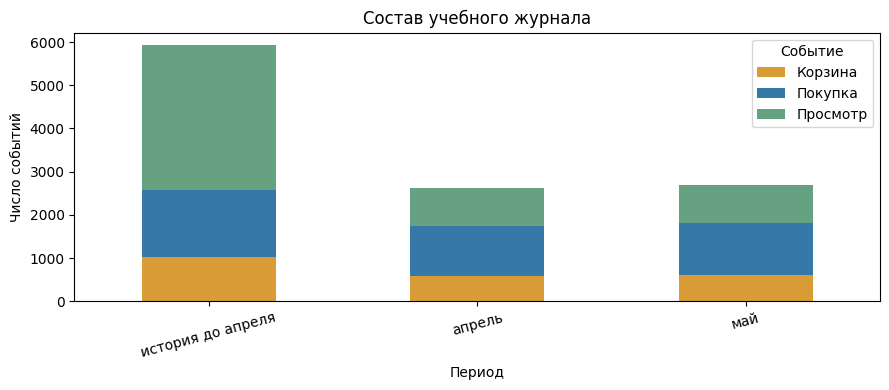

In [7]:
# Шаг М4.01.07 — Состав сигналов и интервалы
events["period"] = np.select([events.timestamp < "2025-04-01", events.timestamp < "2025-05-01"],
                             ["история до апреля","апрель"],default="май")
event_table = pd.crosstab(events.period,events.event_type).reindex(["история до апреля","апрель","май"])
display(event_table)
event_table.rename(columns={"cart":"Корзина","purchase":"Покупка","view":"Просмотр"}).plot.bar(
    stacked=True,color=["#d99b35","#3678a8","#66a182"],rot=15)
plt.xlabel("Период"); plt.legend(title="Событие")
plt.ylabel("Число событий"); plt.title("Состав учебного журнала"); plt.tight_layout(); plt.show()

Обозначения далее: B — бинарная user-item матрица; R — log(1 + сумма весов событий). Строки соответствуют известному реестру пользователей, столбцы — отсортированному каталогу. Пропуск взаимодействия хранится нулём, но не считается доказанным отрицательным отзывом.

Одна ячейка объединяет все разрешённые события пары до границы времени. B отвечает на вопрос о наличии взаимодействия, R — о его агрегированной интенсивности. Преобразование log1p уменьшает влияние многократных повторов и остаётся определённым для нуля.

Пустая ячейка не несёт объяснения отсутствия действия. Причиной могут быть отсутствие показа, неподходящий момент, цена или отсутствие интереса; матрица этого не различает.

In [8]:
# Шаг М4.01.08 — Вес взаимодействия и бинарный факт
weights = {"view":1.0,"cart":3.0,"purchase":5.0}
events["strength"] = events.event_type.map(weights)
pair_example = events[events.timestamp < "2025-04-01"].groupby(["user_id","product_id"]).agg(
    событий=("event_id","size"), сумма_весов=("strength","sum"))
pair_example["R"] = np.log1p(pair_example["сумма_весов"])
pair_example["B"] = 1
display(pair_example.sort_values("событий",ascending=False).head(8))

,,событий,сумма_весов,R,B
user_id,product_id,,,,
126,21,2,6.0,1.945910,1
26,28,2,2.0,1.098612,1
87,94,2,2.0,1.098612,1
46,275,2,2.0,1.098612,1
26,61,2,2.0,1.098612,1
110,340,2,2.0,1.098612,1
130,22,2,2.0,1.098612,1
97,36,2,2.0,1.098612,1


Отображения u_map и i_map связывают внешние ключи с внутренними позициями. Операции матриц корректны только при одинаковом порядке столбцов каталога. Перестановка списка product_id без соответствующей перестановки оценок привела бы к выдаче других товаров при внешне правильной форме массива.

Размер учебной плотной маски известен заранее. При переходе к большим данным необходимо контролировать промежуточные результаты, а не только формат исходной таблицы.

In [9]:
# Шаг М4.01.09 — Общий протокол расчёта
def load_context(phase="validation"):
    if phase not in {"validation", "test"}:
        raise ValueError("Ожидается validation или test")
    catalog = pd.read_csv(DATA_DIR / "reco_catalog.csv").sort_values("product_id").reset_index(drop=True)
    events = pd.read_csv(DATA_DIR / "reco_events.csv", parse_dates=["timestamp"]).drop_duplicates("event_id")
    cut = pd.Timestamp("2025-04-01" if phase == "validation" else "2025-05-01")
    end = pd.Timestamp("2025-05-01" if phase == "validation" else "2025-06-01")
    history = events[events.timestamp < cut].copy()
    future = events[(events.timestamp >= cut) & (events.timestamp < end) & (events.event_type == "purchase")]
    user_ids = np.arange(1, 301)  # Известный учебный реестр, а не признак предпочтения.
    item_ids = catalog.product_id.to_numpy()
    u_map = {int(value): index for index, value in enumerate(user_ids)}
    i_map = {int(value): index for index, value in enumerate(item_ids)}
    history["strength"] = history.event_type.map({"view": 1.0, "cart": 3.0, "purchase": 5.0})
    pairs = history.groupby(["user_id", "product_id"]).strength.sum().reset_index()
    R = sparse.csr_matrix((np.log1p(pairs.strength),
                           (pairs.user_id.map(u_map), pairs.product_id.map(i_map))),
                          shape=(len(user_ids), len(item_ids)))
    B = R.copy()
    B.data[:] = 1.0
    seen = B.toarray().astype(bool)  # Только 300 x 180; полный большой каталог так не разворачивается.
    truth = {int(u): set(g.product_id) - set(item_ids[seen[u_map[int(u)]]])
             for u, g in future.groupby("user_id")}
    purchases = history[history.event_type.eq("purchase")].drop_duplicates(["user_id", "product_id"])
    popularity = purchases.groupby("product_id").size().reindex(item_ids, fill_value=0).to_numpy(float)
    return dict(catalog=catalog, events=events, history=history, R=R, B=B, seen=seen,
                truth=truth, user_ids=user_ids, item_ids=item_ids, u_map=u_map,
                i_map=i_map, popularity=popularity, cut=cut, end=end, phase=phase)

def top_indices(scores, seen, k=10):
    values = np.array(scores, dtype=float, copy=True)
    if values.ndim != 2 or values.shape != seen.shape or not np.isfinite(values).all():
        raise ValueError("Нужна конечная матрица оценок формы user x item")
    values[seen] = -np.inf
    result = []
    for row in values:
        order = np.argsort(-row, kind="stable")
        result.append(order[np.isfinite(row[order])][:k])
    return result

def evaluate(scores, ctx, k=10):
    ranked = top_indices(scores, ctx["seen"], k)
    rows = []
    for u, relevant in ctx["truth"].items():
        if not relevant:
            continue
        ui = ctx["u_map"][u]
        recommended = ctx["item_ids"][ranked[ui]]
        hits = np.isin(recommended, list(relevant)).astype(float)
        discounts = 1 / np.log2(np.arange(2, len(hits) + 2))
        ideal = (1 / np.log2(np.arange(2, min(k, len(relevant)) + 2))).sum()
        positions = np.flatnonzero(hits)
        rows.append(dict(user_id=u, history_size=int(ctx["seen"][ui].sum()), n_truth=len(relevant),
                         precision=float(hits.sum()/k), recall=float(hits.sum()/len(relevant)),
                         ndcg=float(hits @ discounts / ideal), hit=float(hits.any()),
                         mrr=0.0 if not len(positions) else 1.0/(positions[0]+1)))
    return pd.DataFrame(rows)

def summarize(scores, ctx, k=10):
    detail = evaluate(scores, ctx, k)
    ranked = top_indices(scores, ctx["seen"], k)
    evaluated_rows = [ranked[ctx["u_map"][int(u)]] for u in detail.user_id]
    chosen = np.concatenate(evaluated_rows)
    novelty = -np.log2((ctx["popularity"]+1)/(ctx["popularity"].sum()+len(ctx["item_ids"])))
    return pd.Series({"Precision@K":detail.precision.mean(), "Recall@K":detail.recall.mean(),
                      "NDCG@K":detail.ndcg.mean(), "HitRate@K":detail.hit.mean(),
                      "Coverage":len(np.unique(chosen))/len(ctx["item_ids"]),
                      "Novelty":float(novelty[chosen].mean()), "users":len(detail)})

def popular_scores(ctx):
    return np.tile(ctx["popularity"], (len(ctx["user_ids"]), 1))

Данные приведены к двум согласованным представлениям истории. События очищены по event_id; повторные действия сохранены. Правила преобразования истории зафиксированы до сравнения алгоритмов.

## Временная проверка и множество кандидатов

Для validation используются события до 1 апреля 2025 года и покупки апреля. После выбора настроек модель переобучается на событиях до 1 мая; test содержит покупки мая. Границы задаются полуинтервалами: начало включается, конец исключается.

На каждом этапе история, популярность и модель пересчитываются только по доступному прошлому. Каталог и реестр пользователей считаются известными заранее. Само наличие идентификатора в реестре не сообщает модели будущие предпочтения.

Обучающая история расширяется вместе со временем. В апрельской проверке май неизвестен; в майской апрель уже является прошлым. Все алгоритмы на одном этапе получают одинаковую историю и один контрольный горизонт.

Полуинтервалы предотвращают двойное включение события на границе. Событие ровно в начале апреля относится к апрелю и не должно одновременно участвовать в мартовской истории.

In [10]:
# Шаг М4.01.10 — Границы двух этапов
validation = load_context("validation")
test_context = load_context("test")
display(pd.DataFrame([
    {"этап":c["phase"],"история_до":c["cut"],"контроль_до":c["end"],
     "событий_истории":len(c["history"]),"пользователей_с_целью":len(c["truth"])}
    for c in [validation,test_context]]))
assert validation["history"].timestamp.max() < validation["cut"]
assert test_context["history"].timestamp.max() < test_context["cut"]

,этап,история_до,контроль_до,событий_истории,пользователей_с_целью
0,validation,2025-04-01,2025-05-01,5924,290
1,test,2025-05-01,2025-06-01,8534,300


Разреженность означает малую долю наблюдаемых пар среди всех возможных сочетаний. Она усложняет поиск надёжных совпадений: совпадение двух редких историй может опираться всего на один общий товар.

Холодный старт определяется доступной историей, а не возрастом идентификатора. Пользователь может быть зарегистрирован давно и оставаться без событий; карточка может существовать в каталоге, но ещё не иметь взаимодействий.

In [11]:
# Шаг М4.01.11 — Плотность матрицы и холодный старт
R = validation["R"]
display(pd.Series({"пользователей":R.shape[0],"товаров":R.shape[1],"наблюдаемых пар":R.nnz,
                   "доля наблюдаемых пар":R.nnz/np.prod(R.shape),
                   "пользователей без истории":int((np.asarray(R.sum(axis=1)).ravel()==0).sum()),
                   "товаров без истории":int((np.asarray(R.sum(axis=0)).ravel()==0).sum())}).to_frame("значение"))

,значение
пользователей,300.000000
товаров,180.000000
наблюдаемых пар,5040.000000
доля наблюдаемых пар,0.093333
пользователей без истории,20.000000
товаров без истории,9.000000


Множество контрольных покупок содержит уникальные идентификаторы. Для сценария открытия новых товаров из него удалены позиции, уже встречавшиеся в истории. Иначе алгоритму пришлось бы рекомендовать то, что одновременно запрещено маской.

Случайная подвыборка конкурентов меняет трудность задачи. В этом эксперименте все модели проверяются на полном известном каталоге, чтобы различия не объяснялись лёгкими наборами кандидатов.

In [12]:
# Шаг М4.01.12 — История и будущие положительные примеры
user_id = 1
ui = validation["u_map"][user_id]
seen_ids = set(validation["item_ids"][validation["seen"][ui]])
relevant_ids = validation["truth"][user_id]
display(pd.DataFrame({"история":pd.Series(sorted(seen_ids)), "будущие покупки":pd.Series(sorted(relevant_ids))}))
assert seen_ids.isdisjoint(relevant_ids)
display(pd.Series({"всего кандидатов":len(validation["item_ids"]),
                   "после исключения истории":len(validation["item_ids"])-len(seen_ids),
                   "наблюдаемых будущих покупок":len(relevant_ids)}).to_frame("значение"))

,история,будущие покупки
0,5,38.0
1,6,39.0
2,11,45.0
3,24,120.0
4,31,NaN
5,37,NaN
6,52,NaN
7,53,NaN
8,63,NaN
9,68,NaN


,значение
всего кандидатов,180
после исключения истории,162
наблюдаемых будущих покупок,4


Маска применяется до выбора первых K мест. Фильтрация уже обрезанного списка могла бы оставить меньше рекомендаций и исказить сравнение. Стабильное разрешение равенств фиксирует результат даже при одинаковых нулевых оценках.

Технический порядок идентификаторов не является содержательной моделью. Если пользователь получил такой порядок из-за пустого профиля, необходим явно определённый запасной путь.

In [13]:
# Шаг М4.01.13 — Фильтрация и воспроизводимый порядок
toy_scores = np.array([[.8,.8,.1,.7,.0,.3]])
toy_seen = np.array([[False,True,False,False,False,False]])
display(pd.DataFrame({"позиция":np.arange(6),"оценка":toy_scores[0],"уже_seen":toy_seen[0]}))
print("Ранжирование после маски:",top_indices(toy_scores,toy_seen,k=3)[0].tolist())
assert top_indices(toy_scores,toy_seen,3)[0].tolist()==[0,3,5]

,позиция,оценка,уже_seen
0,0,0.8,False
1,1,0.8,True
2,2,0.1,False
3,3,0.7,False
4,4,0.0,False
5,5,0.3,False


Ранжирование после маски: [0, 3, 5]


Проверка соответствует двум последовательным моментам расчёта. Сравнение проводится на полном каталоге после одинаковой маски истории; правила времени и разрешения равенств едины для всех алгоритмов.

## Метрики списка и ручная проверка

Precision@K — число найденных контрольных покупок, делённое на K. Recall@K — число найденных покупок, делённое на размер контрольного множества пользователя. HitRate@K учитывает хотя бы одно попадание.

NDCG@K дополнительно учитывает позиции. Для бинарной релевантности DCG равен сумме hit(r)/log₂(r+1), а нормировка IDCG — значению идеальной выдачи для того же пользователя. Сначала вычисляется метрика каждого пользователя, затем среднее: активный пользователь не получает дополнительный голос.

Величина K относится к доступным местам показа. Precision использует K в знаменателе даже при небольшом числе контрольных покупок, а Recall — размер личного положительного множества. Разные знаменатели отвечают на разные вопросы.

MRR учитывает только самое раннее попадание. Дополнительные релевантные объекты после него не меняют эту метрику, хотя могут быть полезными в реальном списке.

In [14]:
# Шаг М4.01.14 — Расчёт попаданий вручную
hits = np.array([0,1,1,0,0],dtype=float)
n_relevant = 4
manual = pd.Series({"Precision@5":hits.sum()/5,"Recall@5":hits.sum()/n_relevant,
                     "HitRate@5":float(hits.any()),"MRR@5":1/(np.flatnonzero(hits)[0]+1)})
display(manual.to_frame("значение"))

,значение
Precision@5,0.4
Recall@5,0.5
HitRate@5,1.0
MRR@5,0.5


Логарифмический дисконт в DCG уменьшает вклад нижних позиций. Деление на идеальный результат позволяет сопоставлять пользователей с разным числом известных положительных объектов. Для бинарных попаданий идеальная выдача размещает все доступные положительные объекты первыми.

Метрика не оценивает товары вне наблюдаемой разметки. Высокий NDCG на неполном журнале означает хорошее расположение зарегистрированных покупок, а не полное знание интересов.

In [15]:
# Шаг М4.01.15 — Позиция и идеальная нормировка NDCG
discounts=1/np.log2(np.arange(2,7))
dcg=float(hits@discounts)
idcg=float(discounts[:min(5,n_relevant)].sum())
reordered=np.array([1,1,0,0,0],dtype=float)
display(pd.Series({"DCG":dcg,"IDCG":idcg,"NDCG":dcg/idcg,
                   "NDCG при тех же двух попаданиях выше":reordered@discounts/idcg}).to_frame("значение"))

,значение
DCG,1.130930
IDCG,2.561606
NDCG,0.441492
NDCG при тех же двух попаданиях выше,0.636682


Небольшой пример задаёт ожидаемое поведение функции до применения к полному журналу. Проверка чисел необходима, поскольку корректно выполняющийся код может использовать неверный знаменатель, смещение позиции или порядок ключей.

Усреднение по пользователям даёт каждому оцениваемому человеку один голос. Люди без контрольных положительных объектов здесь исключаются из среднего, и их доля должна оставаться наблюдаемой.

In [16]:
# Шаг М4.01.16 — Проверка функции на маленьком примере
toy_ctx={"seen":np.zeros((2,6),dtype=bool),"truth":{1:{1,3},2:{4}},
         "u_map":{1:0,2:1},"item_ids":np.arange(1,7)}
toy_values=np.array([[6,5,4,3,2,1],[6,5,4,3,2,1]],float)
toy_detail=evaluate(toy_values,toy_ctx,k=3)
display(toy_detail)
assert np.isclose(toy_detail.loc[0,"precision"],2/3)
assert toy_detail.loc[0,"recall"]==1
assert toy_detail.loc[1,"hit"]==0

,user_id,history_size,n_truth,precision,recall,ndcg,hit,mrr
0,1,0,2,0.666667,1.0,0.919721,1.0,1.0
1,2,0,1,0.000000,0.0,0.000000,0.0,0.0


Coverage измеряет охват каталога совокупностью оцениваемых списков. Этот показатель отличается от разнообразия внутри одной десятки. Высокий общий охват может сочетаться с однообразными личными списками.

Novelty использует сглаженную частоту покупателей в истории. Сглаживание оставляет конечное значение для товара без покупок. Редкость и полезность различаются: неизвестный товар может быть как удачным открытием, так и неподходящим объектом.

In [17]:
# Шаг М4.01.17 — Качество охвата каталога
display(pd.DataFrame({
    "метрика":["Coverage","Novelty","NDCG@K"],
    "смысл":["Доля каталога, хотя бы раз попавшая в оцениваемые списки",
             "Средняя -log2 сглаженной доли популярности рекомендованных товаров",
             "Среднее качество порядка относительно контрольных покупок"],
    "ограничение":["Не доказывает полезность каждого показанного товара",
                   "Зависит от выбранного определения популярности",
                   "Зависит от полноты журнала и выбранных кандидатов"]}))

,метрика,смысл,ограничение
0,Coverage,"Доля каталога, хотя бы раз попавшая в оцениваемые списки",Не доказывает полезность каждого показанного товара
1,Novelty,Средняя -log2 сглаженной доли популярности рекомендованных товаров,Зависит от выбранного определения популярности
2,NDCG@K,Среднее качество порядка относительно контрольных покупок,Зависит от полноты журнала и выбранных кандидатов


Ручные примеры согласованы с общей функцией оценки. Метрики попаданий, качества порядка и распространённости выдачи измеряют разные свойства результата и рассматриваются совместно.

## Базовые рекомендации и границы выводов

Базовые алгоритмы задают уровень, который требуется улучшить. Популярность вычисляется по числу разных покупателей в доступной истории. Случайная выдача служит контрольной точкой и использует фиксированный генератор.

Майские результаты ниже относятся только к заранее заданной популярности. Настройки будущих персональных моделей подбираются по апрелю; test не используется как таблица для выбора победителя.

Один глобальный рейтинг после персональной маски даёт разные списки разным людям. История влияет на допустимость объектов, однако индивидуальные предпочтения не участвуют в исходном скоринге.

Контрольный столбец будущей покупки добавляется для разбора результата после ранжирования. Использование этой информации при сортировке превратило бы проверку в утечку ответа.

In [18]:
# Шаг М4.01.18 — Выдача популярных новых товаров
pop_scores=popular_scores(validation)
pop_indices=top_indices(pop_scores,validation["seen"],10)[ui]
recommendation=validation["catalog"].iloc[pop_indices][["product_id","name","category"]].copy()
recommendation["будущая покупка"]=recommendation.product_id.isin(validation["truth"][user_id])
display(recommendation)

,product_id,name,category,будущая покупка
17,18,Красота товар 18,Красота,False
102,106,Бытовая техника товар 106,Бытовая техника,False
34,35,Одежда товар 35,Одежда,False
136,168,Дом и сад товар 168,Дом и сад,False
119,127,Электроника товар 127,Электроника,False
0,1,Электроника товар 1,Электроника,False
137,169,Красота товар 169,Красота,False
153,214,Спорт товар 214,Спорт,False
53,54,Дом и сад товар 54,Дом и сад,False
82,83,Дом и сад товар 83,Дом и сад,False


Случайный алгоритм использует тот же каталог и маску, что популярность. Фиксация seed делает конкретную контрольную выдачу повторяемой. Один случайный результат не определяет точное ожидаемое качество.

Все сравниваемые списки имеют одинаковый K. Проверка на разных длинах, разных горизонтах или разных доступных товарах не позволила бы приписать отличие самой модели.

In [19]:
# Шаг М4.01.19 — Случайный и популярный алгоритмы
random_scores=np.random.default_rng(17).random(validation["R"].shape)
baseline_table=pd.DataFrame({"популярность":summarize(pop_scores,validation),
                             "случайный":summarize(random_scores,validation)}).T
display(baseline_table.round(4))

,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users
популярность,0.0303,0.0759,0.0608,0.2724,0.1,6.4356,290.0
случайный,0.0231,0.0578,0.0409,0.2034,1.0,7.7463,290.0


Повторы показывают вариативность только случайного порядка на неизменных пользователях и покупках. Это узкий источник неопределённости. Он не включает сезонность, изменение поведения и ошибки сбора журнала.

Среднее и стандартное отклонение полезны для чтения случайной контрольной точки, но не являются доказательством устойчивости персонального алгоритма на новых месяцах.

In [20]:
# Шаг М4.01.20 — Вариативность случайной проверки
random_checks=pd.DataFrame([
    {"seed":s,**summarize(np.random.default_rng(s).random(validation["R"].shape),validation).to_dict()}
    for s in range(10)])
display(random_checks[["Precision@K","Recall@K","NDCG@K"]].agg(["mean","std","min","max"]).round(4))

,Precision@K,Recall@K,NDCG@K
mean,0.0259,0.0647,0.0471
std,0.0029,0.0072,0.0062
min,0.0207,0.0517,0.0353
max,0.0310,0.0776,0.0585


Увеличение списка даёт больше шансов найти покупку, но расходует внимание пользователя. Поэтому рост полноты не означает автоматического улучшения интерфейса. Фактическое число видимых карточек определяет подходящее K.

Далее K=10 сохраняется при выборе настроек и проверке. Благодаря этому изменение метрики не объясняется незаметным расширением выдачи.

,K,Precision@K,Recall@K,NDCG@K
0,1,0.0517,0.0129,0.0517
1,5,0.0386,0.0483,0.0472
2,10,0.0303,0.0759,0.0608
3,20,0.0331,0.1655,0.0961


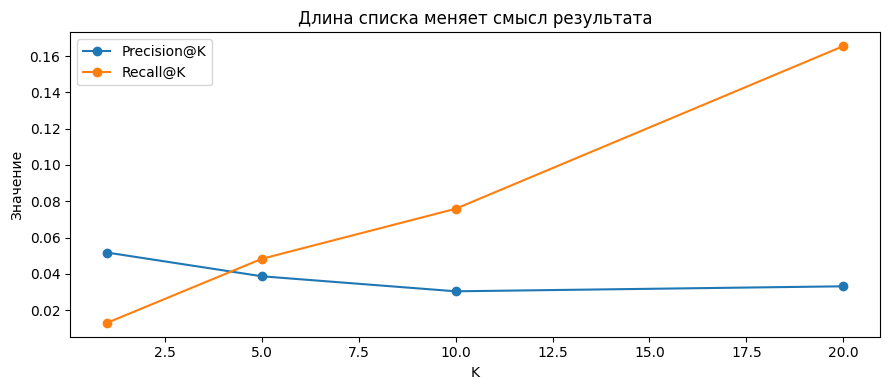

In [21]:
# Шаг М4.01.21 — Длина выдачи и качество
k_table=pd.DataFrame([{"K":k,**summarize(pop_scores,validation,k).to_dict()} for k in [1,5,10,20]])
display(k_table[["K","Precision@K","Recall@K","NDCG@K"]].round(4))
k_table.plot(x="K",y=["Precision@K","Recall@K"],marker="o")
plt.title("Длина списка меняет смысл результата");plt.ylabel("Значение");plt.tight_layout();plt.show()

Среднее по всем пользователям может скрыть проблему холодного старта. Разрез по доступной истории показывает, кто действительно получает персональный сигнал, а кто обслуживается запасным алгоритмом.

Размер группы указывается рядом с качеством. Небольшое число холодных пользователей ограничивает устойчивость оценки; удаление этой группы из отчёта создало бы более привлекательное, но неполное описание системы.

In [22]:
# Шаг М4.01.22 — Оценка пользователей без истории
detail=evaluate(pop_scores,validation)
detail["когорта"]=np.where(detail.history_size.eq(0),"без истории","с историей")
display(detail.groupby("когорта").agg(пользователей=("user_id","size"),
                                      NDCG=("ndcg","mean"),Recall=("recall","mean")).round(4))
assert len(detail)==len(validation["truth"])

,пользователей,NDCG,Recall
когорта,,,
без истории,10,0.0751,0.1250
с историей,280,0.0603,0.0741


Переход к маю обновляет события, а не определение алгоритма. Популярность пересчитана по новому доступному прошлому и проверена на следующем периоде. Именно это соответствует пакетному обновлению снимка.

Отличие результата между месяцами не доказывает улучшение или ухудшение формулы: одновременно меняются история, аудитория и конкретные покупки. Для временной устойчивости нужен ряд таких проверок.

In [23]:
# Шаг М4.01.23 — Независимый период для зафиксированного правила
test_pop=popular_scores(test_context)
display(pd.DataFrame({"апрель":summarize(pop_scores,validation),
                      "май":summarize(test_pop,test_context)}).T.round(4))
assert test_context["cut"]==pd.Timestamp("2025-05-01")

,Precision@K,Recall@K,NDCG@K,HitRate@K,Coverage,Novelty,users
апрель,0.0303,0.0759,0.0608,0.2724,0.1000,6.4356,290.0
май,0.0493,0.1233,0.0872,0.4133,0.1167,6.6245,300.0


Паспорт фиксирует постановку, критерий положительного события, кандидатов, время и правила усреднения. Без этих сведений название метрики недостаточно для интерпретации результата.

Офлайн-проверка оценивает согласование выдачи с наблюдаемыми действиями. Чтобы определить причинное влияние рекомендаций, необходим эксперимент, в котором сравнивается поведение при разных правилах показа, а не только расчёт на сохранённом журнале.

In [24]:
# Шаг М4.01.24 — Паспорт эксперимента
passport=pd.Series({"сценарий":"Новые товары, исключение всех прошлых взаимодействий",
                    "положительный факт":"Покупка в следующем календарном окне",
                    "каталог":"180 известных заранее товаров, без случайной подвыборки кандидатов",
                    "выбор настроек":"Апрель 2025",
                    "финальная проверка":"Май 2025, история обновлена до начала мая",
                    "главная метрика":"Средняя по пользователям NDCG@10",
                    "ограничение":"Синтетические предпочтения, журнал не содержит показов",
                    "масштаб":"Учебные плотные оценки 300 x 180"})
display(passport.to_frame("принятое правило"))

,принятое правило
сценарий,"Новые товары, исключение всех прошлых взаимодействий"
положительный факт,Покупка в следующем календарном окне
каталог,"180 известных заранее товаров, без случайной подвыборки кандидатов"
выбор настроек,Апрель 2025
финальная проверка,"Май 2025, история обновлена до начала мая"
главная метрика,Средняя по пользователям NDCG@10
ограничение,"Синтетические предпочтения, журнал не содержит показов"
масштаб,Учебные плотные оценки 300 x 180


Практический результат — воспроизводимый журнал, очищенные события, единое временное разделение, проверенные метрики и две отправные точки. Дальнейшие алгоритмы используют этот же договор проверки.

Офлайн-качество не равно причинному эффекту от показа рекомендаций. Для проверки влияния на реальное поведение нужны данные о показах, корректный эксперимент, контроль качества выдачи и наблюдение за результатом.

Источники: [неявная обратная связь, Hu, Koren, Volinsky](https://yifanhu.net/PUB/cf.pdf), [NDCG в Scikit-learn](https://scikit-learn.org/1.8/modules/generated/sklearn.metrics.ndcg_score.html).